# ERA5 SST vs COBE SST

**What's in this notebook**

- Compares ERA5 SST against COBE observational SST.
- Percentile method and trend plots.

_Cleaned copy of `era5_sst_vs_cobe.ipynb`. Shared helpers in `functions.py`; outputs stripped — re-run to regenerate figures._


In [1]:
import sys, os
# make this repo's functions.py importable from any subfolder
_p = os.getcwd()
for _ in range(6):
    if os.path.exists(os.path.join(_p, 'functions.py')):
        sys.path.insert(0, _p); break
    _p = os.path.dirname(_p)
from functions import *  # shared helper functions


In [2]:
# Load variables produced by earlier (compute/loader) notebooks.
# Run those first; harmless if there's nothing saved yet.
load_state(globals())


[load_state] loaded 251 variables from /Users/isabelaconde/Documents/GitHub/JRA55-do_ctrl_ERA5-forcings/processed_data/state.pkl
[load_state] available: DA_all, In, Out, STATE_DIR, STATE_FILE, all_trend_percentiles, ax, axes, base_path, basin_cmip, basin_era5, basin_jra55 ...


{'In': ['',
  "# Load Packages\nimport numpy as np\nimport xarray as xr\nimport matplotlib\nimport matplotlib.pyplot as plt\nimport matplotlib.transforms as transforms\nimport cartopy.crs as ccrs\nimport calendar, os, re, datetime\nfrom datetime import datetime as _dt\nfrom pathlib import Path\nfrom matplotlib.lines import Line2D\nimport seaborn as sns\nimport pandas as pd\nimport matplotlib.gridspec as gridspec\nfrom scipy.stats import norm, scoreatpercentile\nfrom mpl_toolkits.axes_grid1 import make_axes_locatable\nimport matplotlib.patches as patches\nfrom matplotlib.gridspec import GridSpec\nfrom xhistogram.xarray import histogram\n\nget_ipython().run_line_magic('matplotlib', 'inline')",
  "import sys, os\n_p = os.getcwd()\nfor _ in range(6):\n    if os.path.exists(os.path.join(_p, 'functions.py')):\n        sys.path.insert(0, _p); break\n    _p = os.path.dirname(_p)\nfrom functions import *  # shared helper functions",
  "def quantiles_xhist(data):\n    hist_T = data.sel(lon = sli

In [3]:
# Load Packages 

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import math
import cartopy.crs as ccrs
import calendar
from matplotlib.lines import Line2D
import os
import re
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import norm
# from mpl_toolkits.basemap import Basemap
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as patches
from scipy.stats import scoreatpercentile
# import xesmf as xe
from matplotlib.gridspec import GridSpec
import matplotlib

%matplotlib inline


## load data and find percentiles 

In [4]:
from xhistogram.xarray import histogram

def percentiles_xhist(data): # find percentiles of SST using xhistogram
    hist_T = data.squeeze()
    weights = np.cos(np.deg2rad(hist_T.lat))
    times = hist_T['time']
    const_area=np.r_[0:1:0.01]
    temps = np.r_[12:34:0.5] # define temperatures for binning 
    
    temps_interp = np.empty([len(times),len(const_area)])
    
    for i in np.r_[0:len(times):1]:  
        h=histogram(hist_T[i],bins=temps,weights=weights).cumsum()
        hh = (h - h[0])/(h[-1]-h[0])
        temps_interp[i]=np.interp(const_area,hh,temps[1:])
    
    
    sst_area= xr.DataArray(temps_interp,coords={'time':times,'area':const_area})

    return(sst_area)

def pacific_mask(sst):

    LonsPts_pos = [130,120,110,110,110,260,270,270,277,291,291,130] #-np.ones(13)*180
    LatsPts_pos =[-20,-10,-5,10,20,20,15,15,10,5,-20,-20]
    
    x_pixel_pos = LonsPts_pos
    y_pixel_pos = LatsPts_pos
    
    temp_list = []
    for a, b in zip(x_pixel_pos, y_pixel_pos):
        temp_list.append([a, b])
    
    polygon = np.array(temp_list)
    
    xv, yv = sst.lon.values, sst.lat.values
    lon2d, lat2d = np.meshgrid(xv, yv)
    points = np.hstack((lon2d.reshape((-1,1)), lat2d.reshape((-1,1))))
    path = matplotlib.path.Path(polygon)
    mask = path.contains_points(points)
    mask.shape = lon2d.shape
    mask_bit_pos = mask*np.ones_like(lon2d)

    mask_mods = mask_bit_pos
    
    mask_mods[mask_mods==0] = np.nan
    return mask_mods


def trend_obs_percentile(data): # find trend of percentile data
    time_axis = np.arange(data.sizes['time'])
    trends = np.empty(data.sizes['area'])
    for i in range(data.sizes['area']):
        y = data[:, i].values
        trends[i] = np.polyfit(time_axis, y, 1)[0]  # slope

    return xr.DataArray(trends, coords={'area': data.area}, dims='area', name='sst_trend')


noaa_sst = xr.open_dataset('/Users/isabelaconde/Desktop/data/conde2025/NOAA_sst.mon.mean.nc').sst.sel(time = slice('1982','2017')).sel(lat = slice(-80,80))
noaa_sst_pacific = (pacific_mask(noaa_sst)*noaa_sst).sel(lat=slice(-20,20), lon = slice(100,300))
noaa_sst_percentiles = percentiles_xhist(noaa_sst_pacific)
noaa_sst_percent_trend = trend_obs_percentile(noaa_sst_percentiles)

cobe_sst = xr.open_dataset('//Users/isabelaconde/Desktop/data/obs_sst/cobe.nc').sst.sel(time = slice('1982','2017')).sortby('lat').rename('sst')

# cm2_trends = xr.open_dataset('/Users/isabelaconde/Desktop/data/ACCESS_CM2/ACCESS-CM2_trends_1982-2017_gr.nc')
cm2_sst  = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS_CM2/cm2__tos_pa.nc').rename('sst')
  
# cm2_percentiles = percentiles_xhist(cm2_sst.rename('sst'))
# cm2_percent_trend = trend_obs_percentile(cm2_percentiles)
cobe_sst_pa  = (pacific_mask(cobe_sst)*cobe_sst).sel(lat=slice(-20,20), lon = slice(110,300))
cobe_percentiles = percentiles_xhist(cobe_sst_pa)
cobe_percent_trend = trend_obs_percentile(cobe_percentiles)



In [11]:
era5_sst = xr.open_dataarray('/Users/isabelaconde/Downloads/data_stream-moda_stepType-avgua.nc')-273.15
era5_sst = era5_sst.rename({
    'valid_time': 'time',
    'latitude': 'lat',
    'longitude': 'lon'
})
era5_sst = pacific_mask(era5_sst)*era5_sst
era5_sst = era5_sst.sortby('lat')
era5_sst = era5_sst.sel(lat=slice(-20,20), lon = slice(110,290))
era5_percentiles = percentiles_xhist(era5_sst)
era5_base_percent_trend = trend_obs_percentile(era5_percentiles)


In [6]:
era5_sst_trend = find_trend_values(era5_sst)
cobe_sst_trend = find_trend_values(cobe_sst_pa)
noaa_sst_trend  = find_trend_values(noaa_sst_pacific)
# era5_sst_trend.plot()

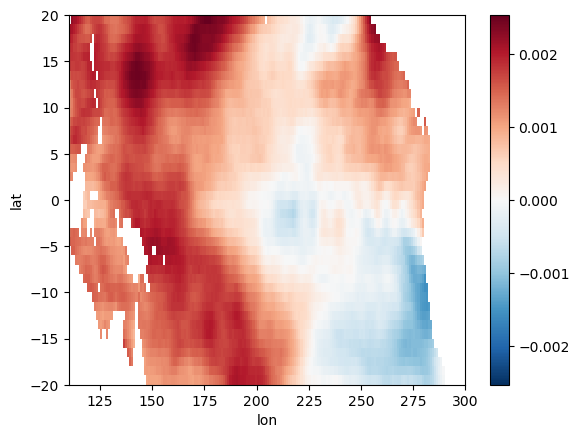

In [7]:
# cobe_percent_trend.plot()
# cobe_pa_sst = cobe_sst.sel(lat=slice(-20,20), lon = slice(110,300)) #(pacific_mask(cobe_sst)*cobe_sst).sel(lat=slice(-20,20), lon = slice(110,300))
cobe_sst_trend.plot()

In [8]:
control_percent_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_control.nc')
era5_percent_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_era5.nc')
# perturb_percent_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/perturb_merra2_percentile_trend.nc')
# # perturb_percent_era5_uas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/perturb_percentile_era5_uas_trend.nc')
# perturb_percent_era5_uas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/1deg_jra55_iaf_era5_uas_trend_percentile.nc')
# perturb_percent_era5_uas_vas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_uas_vas.nc')
# perturb_percent_era5_huss_tas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_huss_tas.nc')
# perturb_percent_era5_rsds_rlds_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_rsds_rlds.nc')
# perturb_percent_era5_winds = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_era5_winds.nc')
# perturb_percent_all_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_all_trend.nc')
# perturb_percent_winds_mean_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/perturb_percentile_trend_uas_vas_mean_trend.nc')
# perturb_percent_cm2_winds_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_cm2_uas_vas_trend.nc')

# Plots 

1. trend at each percent plot 
2. trend at each percent difference from era5

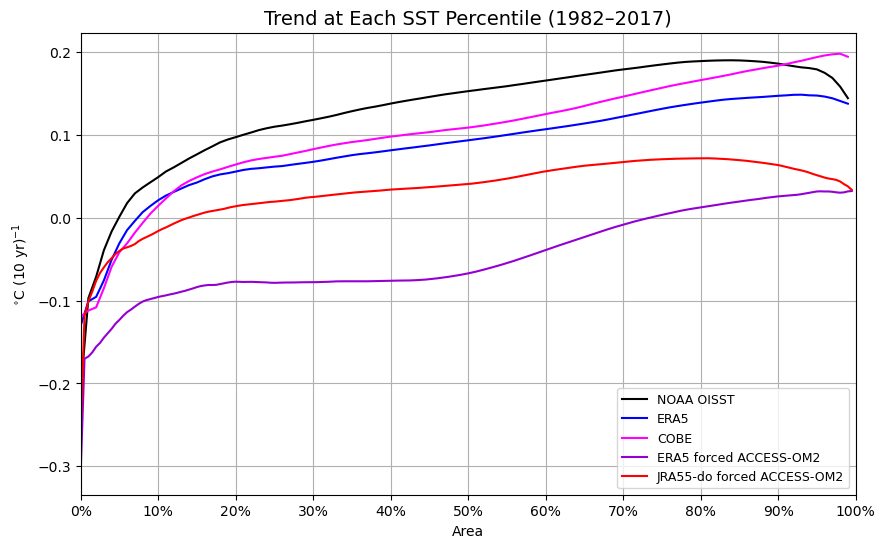

In [18]:
fig, axes = plt.subplots(figsize=(10, 6))



# NOAA observational line
axes.plot(noaa_sst_percent_trend.area.values, noaa_sst_percent_trend.values * 10 * 12,
          color='k', label='NOAA OISST')

axes.plot(era5_base_percent_trend.area.values, era5_base_percent_trend.values * 10 * 12, 
            color='blue', label='ERA5')

axes.plot(cobe_percent_trend.area.values, cobe_percent_trend.values * 10 * 12, 
            color='magenta', label='COBE')
(era5_percent_trend * 12 * 10).plot(
    ax=axes,
    color='darkviolet',
    label='ERA5 forced ACCESS-OM2',
    lw=1.5
)
# -------------------------
# ACCESS-OM2 runs
# -------------------------
(control_percent_trend*12*10).plot(ax=axes, label='JRA55-do forced ACCESS-OM2', color='red',lw=1.5)
# -------------------------
# Formatting
# -------------------------
axes.set_xticks(np.linspace(0, 1, 11))
axes.set_xticklabels([f'{int(x*100)}%' for x in np.linspace(0, 1, 11)])
axes.grid(True)
axes.legend(loc='lower right', fontsize=9)
axes.set_xlim(0, 1)
axes.set_ylabel(r'$^{\circ}$C (10 yr)$^{-1}$')
axes.set_xlabel('Area')
plt.title('Trend at Each SST Percentile', fontsize=14)

outpath = "/Users/isabelaconde/Desktop/trend_percent_era5_vs_cobe.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")


In [12]:
cw_grad_noaa = noaa_sst_percent_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - noaa_sst_percent_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
cw_grad_era5 = era5_base_percent_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - era5_base_percent_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
cw_grad_cobe  = cobe_percent_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - cobe_percent_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
cw_jra55_om2 = control_percent_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - control_percent_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
cw_era5_om2 = era5_percent_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - era5_percent_trend.sel(area = slice(0,0.5)).mean(dim = 'area')

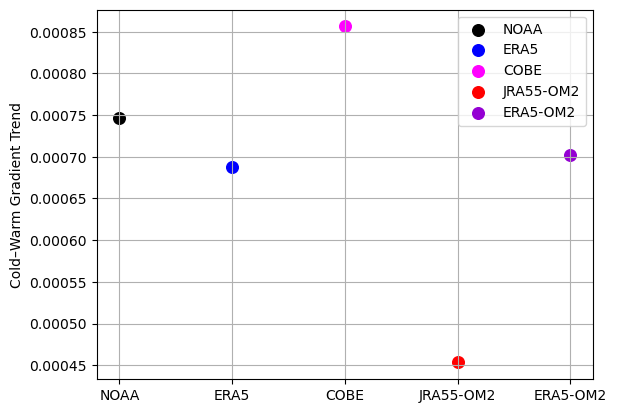

In [13]:
import matplotlib.pyplot as plt

labels = ['NOAA', 'ERA5', 'COBE', 'JRA55-OM2', 'ERA5-OM2']
values = [
    cw_grad_noaa.item(),
    cw_grad_era5.item(),
    cw_grad_cobe.item(),
    cw_jra55_om2.item(),
    cw_era5_om2.item()
]

fig, ax = plt.subplots()

colors = ['black',  'blue','magenta', 'red', 'darkviolet']

for i, (lab, val, c) in enumerate(zip(labels, values, colors)):
    ax.scatter(i, val, color=c, label=lab, s =70)

ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.grid(True)

ax.set_ylabel('Cold–Warm Gradient Trend')
ax.legend()

plt.show()

/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_41941/4248976202.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.90, 1], pad=0.2)


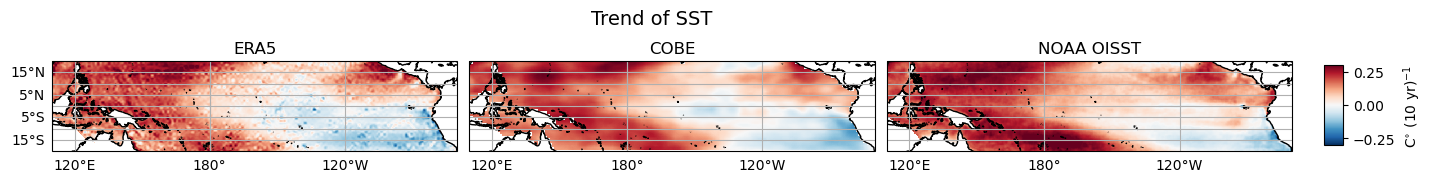

In [14]:

# target grid = ERA5
lat, lon = era5_sst_trend.lat, era5_sst_trend.lon
on_era5  = lambda da: da.interp(lat=lat, lon=lon)

era5  = era5_sst_trend
jra55 = on_era5(cobe_sst_trend)

das = [
    ("ERA5",            era5 * 10 * 12),
    ("COBE",           jra55 * 10 * 12 ),
    ("NOAA OISST", noaa_sst_trend * 10 * 12),
]

# --- common colour limits (symmetric about 0) ---
stack = xr.concat([d for _, d in das], dim="panel")
v = 0.3
vmin, vmax = -v, v  # symmetric

# --- map setup (same style as your final 1x3 example) ---
proj = ccrs.PlateCarree(central_longitude=180)
pc0  = ccrs.PlateCarree()
extent = [110, 290, -20, 20]

fig = plt.figure(figsize=(16, 2))
gs = GridSpec(1, 3, figure=fig, wspace=0.03)

axes = [fig.add_subplot(gs[0, c], projection=proj) for c in range(3)]

ims = []
for ax, (title, da) in zip(axes, das):
    im = ax.pcolormesh(
        da.lon, da.lat, da,
        cmap="RdBu_r", vmin=vmin, vmax=vmax,
        transform=pc0
    )
    ax.set_extent(extent, crs=pc0)
    ax.coastlines()
    ax.set_title(title, fontsize=12)
    ims.append(im)

# gridlines: labels only on leftmost
for i, ax in enumerate(axes):
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    if i != 0:
        gl.left_labels = False

# colorbar
cax = fig.add_axes([0.92, 0.30, 0.012, 0.40])
fig.colorbar(ims[0], cax=cax, label=r'C$^{\circ}$ (10 yr)$^{-1}$')

plt.tight_layout(rect=[0, 0, 0.90, 1], pad=0.2)
plt.suptitle('Trend of SST', fontsize=14, y=0.98)
plt.show()


NameError: name 'ke_trend_3hrly_jra55' is not defined

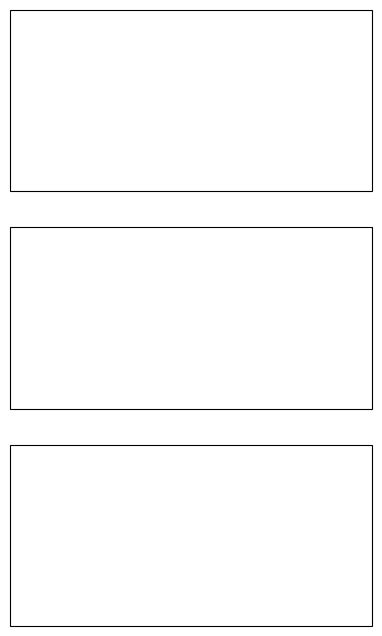

In [15]:

fig, axes = plt.subplots(
    3, 1,
    figsize=(10, 8),
    subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)}
)

plots = [
    (ke_trend_3hrly_jra55* 29220, -5e-9, 5e-9, "RdBu_r", "JRA55-do"),
    (ke_trend_3hrly_era5* 29220, -5e-9, 5e-9, "RdBu_r", "ERA5"),
    ((ke_trend_3hrly_era5 - ke_trend_3hrly_jra55)* 29220,  -5e-9, 5e-9, "RdBu_r", "ERA5 - JRA55-do")
]

for i, (ax, (da, vmin, vmax, cmap, title)) in enumerate(zip(axes, plots)):
    da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
        add_colorbar=False
    )
    
    ax.set_extent([110, 290, -20, 20], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="white", zorder=10)
    ax.coastlines()
    ax.set_title(title)

    gl = ax.gridlines(draw_labels=True, linewidth=0.5, linestyle="--")
    
    # only left subplot shows latitude labels
    gl.top_labels = False
    gl.left_labels = True
    gl.right_labels = False

    gl.bottom_labels = True    
    if i == 2:
        gl.bottom_labels = True
    else:
        gl.bottom_labels = False

# colorbars
cbar1 = fig.colorbar(
    axes[0].collections[0],
    ax=axes[:2],
    orientation="vertical",
    fraction=0.1,
    pad=0.02,
    shrink=0.9
)

cbar2 = fig.colorbar(
    axes[2].collections[0],
    ax=axes[2],
    orientation="vertical",
    fraction=0.1,
    pad=0.02,
    shrink=0.8
)

plt.show()

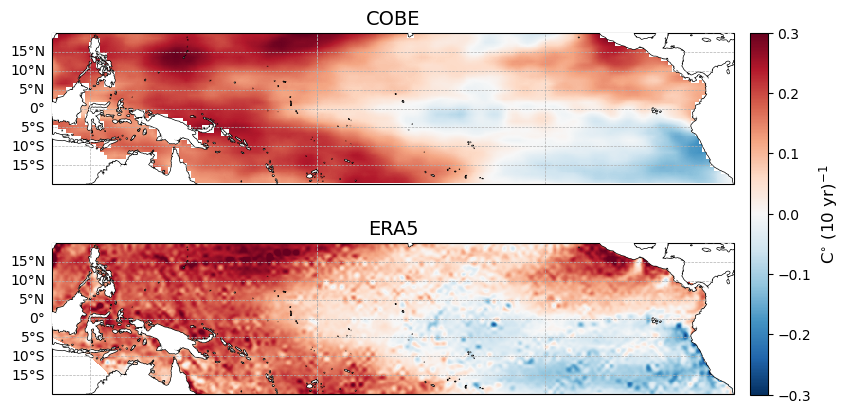

In [16]:
import cartopy.feature as cfeature

# target grid = ERA5
lat, lon = era5_sst_trend.lat, era5_sst_trend.lon
on_era5  = lambda da: da.interp(lat=lat, lon=lon)

era5  = era5_sst_trend * 10 * 12
cobe  = on_era5(cobe_sst_trend) * 10 * 12
noaa  = noaa_sst_trend * 10 * 12

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 5),
    subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)}
)

plots = [
    (cobe, -0.3, 0.3, "RdBu_r", "COBE"),
    (era5, -0.3, 0.3, "RdBu_r", "ERA5"),
]

for i, (ax, (da, vmin, vmax, cmap, title)) in enumerate(zip(axes, plots)):

    da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
        add_colorbar=False
    )

    ax.set_extent([110, 290, -20, 20], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="white", zorder=10)
    ax.coastlines()
    ax.set_title(title, fontsize=14)

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        linestyle="--"
    )

    gl.top_labels = False
    gl.left_labels = True
    gl.right_labels = False

    if i == 2:
        gl.bottom_labels = True
    else:
        gl.bottom_labels = False

# colorbars
cbar1 = fig.colorbar(
    axes[0].collections[0],
    ax=axes[:2],
    orientation="vertical",
    fraction=0.1,
    pad=0.02,
    shrink=0.94
    )

cbar1.set_label(
    r"C$^{\circ}$ (10 yr)$^{-1}$",
    fontsize=12
)




plt.show()

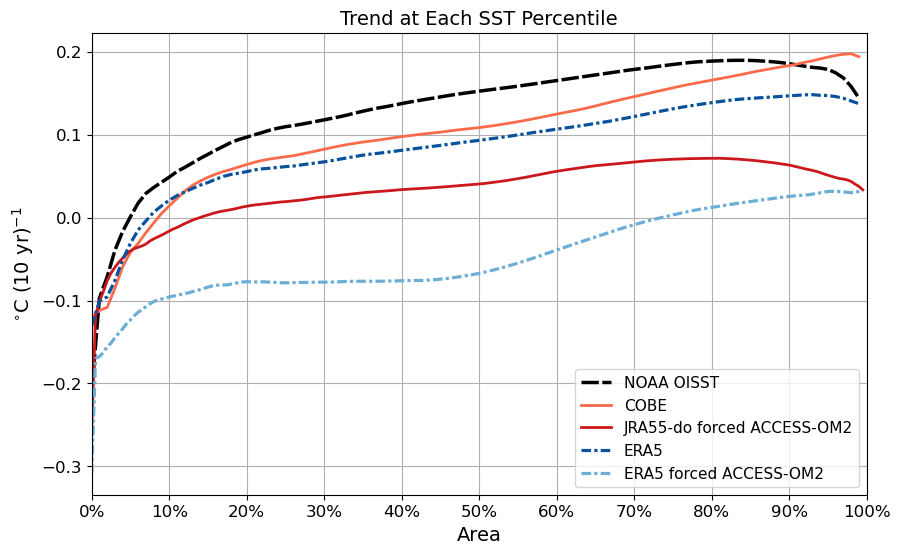

In [40]:
fig, axes = plt.subplots(figsize=(10, 6))

# Two colour families: blues (ERA5 pair), reds (COBE / JRA55 pair), NOAA black

# NOAA observational line
axes.plot(noaa_sst_percent_trend.area.values, noaa_sst_percent_trend.values * 10 * 12,
          color='#000000', label='NOAA OISST', lw=2.5,linestyle=(0,(5,1)))

# COBE / JRA55 family (reds)
axes.plot(cobe_percent_trend.area.values, cobe_percent_trend.values * 10 * 12,
            color='#fb6a4a', label='COBE', lw=2)

(control_percent_trend*12*10).plot(ax=axes, label='JRA55-do forced ACCESS-OM2', color='#cb181d', lw=2)

# ERA5 family (blues, densely dashed)
axes.plot(era5_base_percent_trend.area.values, era5_base_percent_trend.values * 10 * 12,
            color='#08519c', label='ERA5', lw=2.3, linestyle=(0, (3,1,1,1)))

(era5_percent_trend * 12 * 10).plot(
    ax=axes,
    color='#6baed6',
    label='ERA5 forced ACCESS-OM2',
    lw=2.3,
    linestyle=(0, (3,1,1,1))
)
# -------------------------
# Formatting
# -------------------------
axes.set_xticks(np.linspace(0, 1, 11))
axes.set_xticklabels([f'{int(x*100)}%' for x in np.linspace(0, 1, 11)])
axes.grid(True)
axes.legend(loc='lower right', fontsize=11)
axes.set_xlim(0, 1)
axes.set_ylabel(r'$^{\circ}$C (10 yr)$^{-1}$', fontsize=14)
axes.set_xlabel('Area', fontsize=14)
axes.tick_params(axis='both', labelsize=12)
plt.title('Trend at Each SST Percentile', fontsize=14)

outpath = "/Users/isabelaconde/Desktop/trend_percent_era5_vs_cobe.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

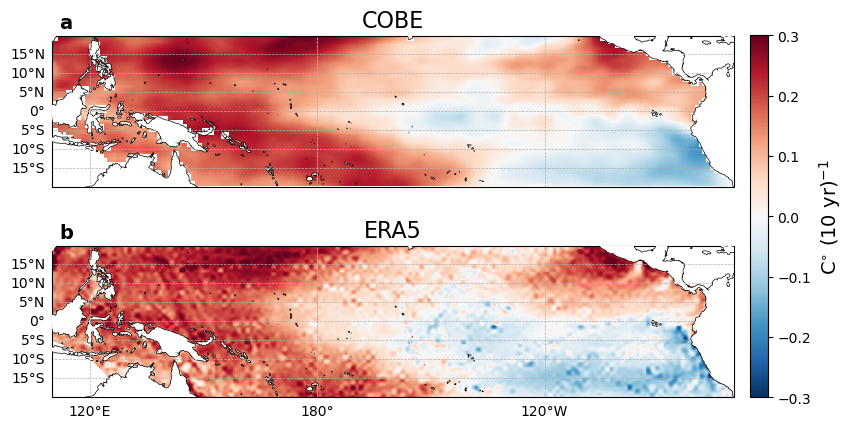

In [39]:
import cartopy.feature as cfeature

# target grid = ERA5
lat, lon = era5_sst_trend.lat, era5_sst_trend.lon
on_era5  = lambda da: da.interp(lat=lat, lon=lon)

era5  = era5_sst_trend * 10 * 12
cobe  = on_era5(cobe_sst_trend) * 10 * 12
noaa  = noaa_sst_trend * 10 * 12

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 5),
    subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)}
)

plots = [
    (cobe, -0.3, 0.3, "RdBu_r", "COBE"),
    (era5, -0.3, 0.3, "RdBu_r", "ERA5"),
]

panel_labels = ["a", "b"]

for i, (ax, (da, vmin, vmax, cmap, title)) in enumerate(zip(axes, plots)):

    da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
        add_colorbar=False
    )

    ax.set_extent([110, 290, -20, 20], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="white", zorder=10)
    ax.coastlines()
    ax.set_title(title, fontsize=16)

    # panel label
    ax.text(
        0.01, 1.02, f"{panel_labels[i]}",
        transform=ax.transAxes,
        fontsize=14, fontweight="bold",
        va="bottom", ha="left"
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        linestyle="--"
    )

    gl.top_labels = False
    gl.left_labels = True
    gl.right_labels = False

    if i == len(axes) - 1:
        gl.bottom_labels = True
    else:
        gl.bottom_labels = False

# colorbars
cbar1 = fig.colorbar(
    axes[0].collections[0],
    ax=axes[:2],
    orientation="vertical",
    fraction=0.1,
    pad=0.02,
    shrink=0.94
    )

cbar1.set_label(
    r"C$^{\circ}$ (10 yr)$^{-1}$",
    fontsize=14
)

outpath = "/Users/isabelaconde/Desktop/sst_trend_maps_cobe_era5.png"
fig.savefig(outpath, format="png", dpi=300, bbox_inches="tight")

In [ ]:
# Save this notebook's variables so later (plotting) notebooks can load them.
save_state(globals())
